In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

results_dir = Path("../evaluation/results")

files = sorted(
    results_dir.glob("benchmark_*.json")
)

if not files:
    raise FileNotFoundError("No benchmark results found.")

latest_file = files[-1]

with latest_file.open(encoding="utf-8") as file:
    report = json.load(file)

df = pd.DataFrame(report["results"])

df.head()

,id,category,prompt,expected_calls,actual_calls,answer,error,tool_selection_correct,arguments_correct,argument_accuracy,execution_success,passed,latency,llm_calls,tool_calls,input_tokens,output_tokens,llm_latency,tool_execution_time
0,T01,price_lookup,What is the latest stock price of Apple?,"[{'tool': 'get_latest_price', 'arguments': {'s...","[{'tool': 'get_latest_price', 'arguments': {'s...",The latest available daily closing price of Ap...,None,True,True,1.0,True,True,19.991700,2,1,1521,71,19.178600,0.812799
1,T02,price_lookup,엔비디아의 최신 주가를 알려줘.,"[{'tool': 'get_latest_price', 'arguments': {'s...","[{'tool': 'get_latest_price', 'arguments': {'s...",엔비디아(NVDA)의 최신 주가(2026년 11월 24일 기준)는 **155.38 ...,None,True,True,1.0,True,True,22.078464,2,1,1528,92,21.899001,0.179222
2,T03,price_lookup,삼성전자의 최신 주가를 알려줘.,"[{'tool': 'get_latest_price', 'arguments': {'s...","[{'tool': 'get_latest_price', 'arguments': {'s...",삼성전자(005930.KS)의 최신 주가(2026년 11월 25일 기준)는 **17...,None,True,True,1.0,True,True,33.301922,2,1,1536,118,32.974620,0.326988
3,T04,financial_analysis,애플의 최근 1년간 Sharpe Ratio를 계산해 줘.,"[{'tool': 'analyze_stock', 'arguments': {'symb...","[{'tool': 'analyze_stock', 'arguments': {'symb...",애플(AAPL)의 최근 1년간 **Sharpe Ratio**는 **0.97**입니다...,None,True,True,1.0,True,True,79.416837,2,1,2344,280,79.189562,0.226871
4,T05,financial_analysis,Analyze Microsoft's volatility over the past 2...,"[{'tool': 'analyze_stock', 'arguments': {'symb...","[{'tool': 'analyze_stock', 'arguments': {'conf...","Microsoft's volatility over the past 2 years, ...",None,True,True,1.0,True,True,71.023018,2,1,2323,325,70.649848,0.372945


In [2]:
pd.Series(report["summary"])

total_tests                   10.000000
passed_tests                  10.000000
pass_rate                      1.000000
tool_selection_accuracy        1.000000
argument_accuracy              1.000000
average_latency               63.914688
median_latency                73.788876
p95_latency                   96.073432
average_llm_calls              1.700000
total_input_tokens         16959.000000
total_output_tokens         2830.000000
total_benchmark_time         639.146883
dtype: float64

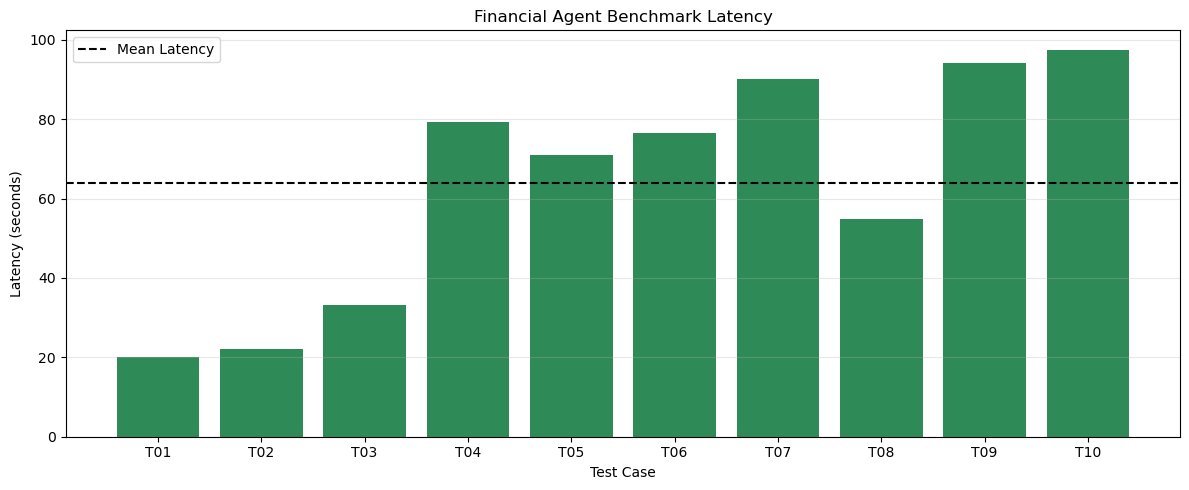

In [3]:
colors = df["passed"].map({
    True: "seagreen",
    False: "indianred"
})

plt.figure(figsize=(12, 5))

plt.bar(
    df["id"],
    df["latency"],
    color=colors
)

plt.axhline(
    df["latency"].mean(),
    linestyle="--",
    color="black",
    label="Mean Latency"
)

plt.title("Financial Agent Benchmark Latency")
plt.xlabel("Test Case")
plt.ylabel("Latency (seconds)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

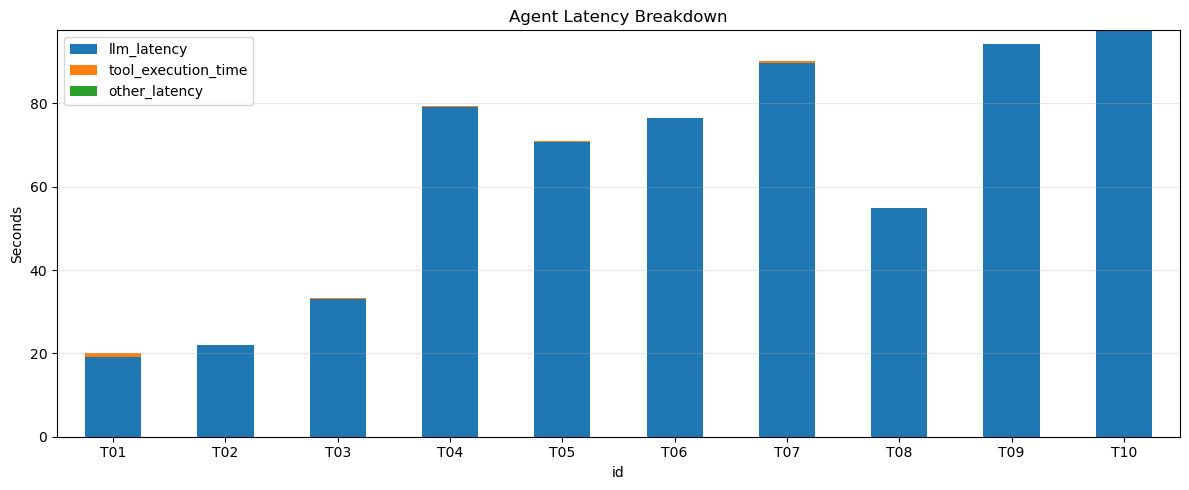

In [4]:
df["other_latency"] = (
    df["latency"]
    - df["llm_latency"]
    - df["tool_execution_time"]
).clip(lower=0)

df.set_index("id")[
    [
        "llm_latency",
        "tool_execution_time",
        "other_latency"
    ]
].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 5)
)

plt.title("Agent Latency Breakdown")
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
category_summary = df.groupby("category").agg(
    tests=("id", "count"),
    pass_rate=("passed", "mean"),
    tool_accuracy=("tool_selection_correct", "mean"),
    average_latency=("latency", "mean"),
    average_input_tokens=("input_tokens", "mean"),
    average_output_tokens=("output_tokens", "mean")
)

category_summary.round(3)

,tests,pass_rate,tool_accuracy,average_latency,average_input_tokens,average_output_tokens
category,,,,,,
conceptual,3,1.0,1.0,82.234,698.000,419.667
financial_analysis,3,1.0,1.0,75.665,2334.000,314.667
multi_asset,1,1.0,1.0,90.078,3278.000,346.000
price_lookup,3,1.0,1.0,25.124,1528.333,93.667


In [6]:
failed_cases = df.loc[
    ~df["passed"],
    [
        "id",
        "prompt",
        "expected_calls",
        "actual_calls",
        "answer",
        "error"
    ]
]

failed_cases

,id,prompt,expected_calls,actual_calls,answer,error


In [7]:
for _, row in df.iterrows():

    print("=" * 70)
    print("Test:", row["id"])
    print("Question:", row["prompt"])
    print("Tool calls:", row["actual_calls"])
    print("Answer:", row["answer"])

Test: T01
Question: What is the latest stock price of Apple?
Tool calls: [{'tool': 'get_latest_price', 'arguments': {'symbol': 'AAPL'}, 'success': True, 'execution_time': 0.8127992500085384}]
Answer: The latest available daily closing price of Apple (AAPL) is **$354.07** USD, as of **November 24, 2026**, according to **Yahoo Finance via yfinance**.
Test: T02
Question: 엔비디아의 최신 주가를 알려줘.
Tool calls: [{'tool': 'get_latest_price', 'arguments': {'symbol': 'NVDA'}, 'success': True, 'execution_time': 0.17922229098621756}]
Answer: 엔비디아(NVDA)의 최신 주가(2026년 11월 24일 기준)는 **155.38 USD**입니다.  
이 주가는 **최근 가용일자 closing price**이며, 데이터 출처는 **Yahoo Finance**입니다.
Test: T03
Question: 삼성전자의 최신 주가를 알려줘.
Tool calls: [{'tool': 'get_latest_price', 'arguments': {'symbol': '005930.KS'}, 'success': True, 'execution_time': 0.3269881670130417}]
Answer: 삼성전자(005930.KS)의 최신 주가(2026년 11월 25일 기준)는 **170,700 원**입니다.  
- **통화**: 원화(KRW)  
- **데이터 유형**: 가장 최근 가용일자 종가  
- **데이터 출처**: Yahoo Finance via yfinance
Test: T04
Que